# Experiment 6: A Render Failure Set and Automatic Triage

In Experiments 1 to 3 I found render failures **by looking**: a fireplace became a window, sofas changed color, the model invented a floor lamp. A product team needs this **automatically**: every time a model or setting changes, run a fixed set of renders and see which failures got better or worse.

**What this notebook builds**
1. **A failure set**: renders of the same rooms made with settings that fail in different ways.
2. **Automatic detectors**, one per failure type.
3. **Human labels**: I look at each render and mark the real failures.
4. **Detector check**: how often do the detectors agree with me (precision and recall)?
5. **A triage report**: which settings fail most, and how.

| Failure type | How it is detected |
|---|---|
| **Color shift** | Mean CIEDE2000 ΔE between the original and the render |
| **Lost structure** | Edge recall: share of the original edges still in the render |
| **Bent or missing lines** | Line recall with OpenCV's line detector (walls, windows, cabinets) |
| **Window changed** | A segmentation model (SegFormer, ADE20K) finds windows in both images; low overlap (IoU) = changed, removed or added |
| **Artwork changed** | The same for paintings and pictures |
| **Invented or removed objects** | Object classes that cover >1% of one image but are almost absent (<0.2%) in the other |
| **Layout changed** | Share of pixels that get the same object label in both images |

Part A needs a GPU (about 5 minutes). Parts B to E also run on a CPU.

## 1. Setup

In [1]:
!pip uninstall -y torchao
!pip install -q diffusers transformers accelerate opencv-python

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [2]:
import torch, cv2, numpy as np, pandas as pd, os, glob
from PIL import Image
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE)
W, H = 768, 432

device: cuda


## 2. Upload room photos
Upload **3 to 8 interior photos** (the more rooms, the more reliable the numbers). Different room types and some with windows and paintings work best.

*Already have renders?* Upload pairs named `room1__original.jpg`, `room1__mysetting.jpg` … and skip Part A.

In [3]:
from google.colab import files
uploaded = files.upload()
os.makedirs("set", exist_ok=True)

def load(p):
    return Image.open(p).convert("RGB").resize((W, H))

originals = {}
for i, name in enumerate(sorted(uploaded), start=1):
    if "__" in name:                                   # already a render pair
        room, setting = name.rsplit(".", 1)[0].split("__")
        load(name).save(f"set/{room}__{setting}.jpg", quality=95)
        if setting == "original": originals[room] = load(name)
    else:
        room = f"room{i}"
        originals[room] = load(name); originals[room].save(f"set/{room}__original.jpg", quality=95)
print(list(originals))

Saving living-room.jpg to living-room.jpg
Saving livspace4.png to livspace4.png
Saving livspace5.png to livspace5.png
Saving open-plan.jpg to open-plan.jpg
Saving room.jpg to room.jpg
['room1', 'room2', 'room3', 'room4', 'room5']


## Part A: Build the failure set (GPU)
Five settings, from my earlier experiments, that fail in different ways:

| Setting | What it is | Expected failure |
|---|---|---|
| `canny_only` | ControlNet with edges only, no original photo | Colors and materials change |
| `img2img_0.5` | Canny + original photo, strength 0.5 | Mostly safe |
| `img2img_0.7` | Strength 0.7 | Some drift |
| `img2img_0.9` | Strength 0.9, guidance 12 | Strong drift, invented objects |
| `inpaint_floor` | Only the floor is repainted | Safest outside the floor |

In [4]:
from diffusers import (ControlNetModel, StableDiffusionControlNetPipeline,
                       StableDiffusionControlNetImg2ImgPipeline, StableDiffusionControlNetInpaintPipeline)
from transformers import SegformerImageProcessor, SegformerForSemanticSegmentation

dtype = torch.float16 if DEVICE == "cuda" else torch.float32
cn = ControlNetModel.from_pretrained("lllyasviel/sd-controlnet-canny", torch_dtype=dtype)
p_i2i = StableDiffusionControlNetImg2ImgPipeline.from_pretrained(
    "stable-diffusion-v1-5/stable-diffusion-v1-5", controlnet=cn, torch_dtype=dtype, safety_checker=None).to(DEVICE)
p_t2i = StableDiffusionControlNetPipeline(**{k: v for k, v in p_i2i.components.items() if k != "image_encoder"})
p_inp = StableDiffusionControlNetInpaintPipeline(**{k: v for k, v in p_i2i.components.items() if k != "image_encoder"})
for p in (p_i2i, p_t2i, p_inp): p.set_progress_bar_config(disable=True)

seg_name = "nvidia/segformer-b2-finetuned-ade-512-512"
seg_proc = SegformerImageProcessor.from_pretrained(seg_name)
seg_model = SegformerForSemanticSegmentation.from_pretrained(seg_name).to(DEVICE).eval()
LABELS = {i: l.split(",")[0].strip() for i, l in seg_model.config.id2label.items()}
CLS = {name: i for i, name in LABELS.items()}

prompt = "photorealistic interior render, light oak wooden floor, natural daylight"
negative = "blurry, distorted, low quality, deformed"
SEED, STEPS = 42, 25

def canny_map(img):
    e = cv2.Canny(np.array(img), 100, 200); return Image.fromarray(np.stack([e] * 3, -1))

def segment(img):
    x = seg_proc(images=img, return_tensors="pt").to(DEVICE)
    with torch.no_grad():
        logits = seg_model(**x).logits
    logits = torch.nn.functional.interpolate(logits, size=(H, W), mode="bilinear", align_corners=False)
    return logits.argmax(1)[0].cpu().numpy()

def floor_mask(img):
    m = (segment(img) == CLS["floor"]).astype(np.uint8)
    return Image.fromarray(cv2.dilate(m, np.ones((9, 9), np.uint8)) * 255)

def g(): return torch.Generator(device="cpu").manual_seed(SEED)

for room, img in originals.items():
    edges = canny_map(img)
    p_t2i(prompt, negative_prompt=negative, image=edges, width=W, height=H, num_inference_steps=STEPS,
          generator=g()).images[0].save(f"set/{room}__canny_only.jpg", quality=95)
    for s, gs in [(0.5, 7.5), (0.7, 7.5), (0.9, 12.0)]:
        p_i2i(prompt, negative_prompt=negative, image=img, control_image=edges, strength=s, guidance_scale=gs,
              num_inference_steps=STEPS, generator=g()).images[0].save(f"set/{room}__img2img_{s}.jpg", quality=95)
    mask = floor_mask(img)
    raw = p_inp(prompt, negative_prompt=negative, image=img, mask_image=mask, control_image=edges,
                width=W, height=H, num_inference_steps=STEPS, generator=g()).images[0]
    p_inp.image_processor.apply_overlay(p_inp.mask_processor.blur(mask, blur_factor=4), img, raw
                                        ).save(f"set/{room}__inpaint_floor.jpg", quality=95)
    print(room, "done")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


config.json:   0%|          | 0.00/920 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B / 1.45GB            

diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

... (9 outputs left out)

Loading weights:   0%|          | 0/380 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  110MB            

model.safetensors: downloading bytes:           |  0.00B            

room1 done
room2 done
room3 done
room4 done
room5 done


## Part B: Automatic detectors
Each detector gives a **number** and a **flag** (number past a threshold). The thresholds are first guesses; Part D checks them against my own labels.

In [5]:
from skimage.color import rgb2lab, deltaE_ciede2000
if "seg_model" not in globals():          # Part A skipped: load only the segmentation model
    from transformers import SegformerImageProcessor, SegformerForSemanticSegmentation
    seg_name = "nvidia/segformer-b2-finetuned-ade-512-512"
    seg_proc = SegformerImageProcessor.from_pretrained(seg_name)
    seg_model = SegformerForSemanticSegmentation.from_pretrained(seg_name).to(DEVICE).eval()
    LABELS = {i: l.split(",")[0].strip() for i, l in seg_model.config.id2label.items()}
    CLS = {name: i for i, name in LABELS.items()}
    def segment(img):
        x = seg_proc(images=img, return_tensors="pt").to(DEVICE)
        with torch.no_grad():
            logits = seg_model(**x).logits
        logits = torch.nn.functional.interpolate(logits, size=(H, W), mode="bilinear", align_corners=False)
        return logits.argmax(1)[0].cpu().numpy()

THRESH = {"color_shift": 10.0, "lost_structure": 0.85, "bent_lines": 0.70,
          "region_iou": 0.50, "layout": 0.70, "present": 0.01, "absent": 0.002}
FAILURES = ["color_shift", "lost_structure", "bent_lines", "window_changed",
            "artwork_changed", "invented_or_removed", "layout_changed"]
WINDOW, PAINTING = CLS["windowpane"], CLS["painting"]
IGNORE = {CLS[c] for c in ["wall", "floor", "ceiling"]}       # large surfaces, not "objects"
lsd = cv2.createLineSegmentDetector()

def edge_recall(o, r):
    eo = cv2.Canny(o, 100, 200) > 0
    er = cv2.dilate((cv2.Canny(r, 100, 200) > 0).astype(np.uint8), np.ones((5, 5), np.uint8)) > 0
    return (eo & er).sum() / max(eo.sum(), 1)

def line_map(a, min_len=30):
    lines = lsd.detect(cv2.cvtColor(a, cv2.COLOR_RGB2GRAY))[0]
    m = np.zeros(a.shape[:2], np.uint8)
    if lines is not None:
        for x1, y1, x2, y2 in lines.reshape(-1, 4):
            if np.hypot(x2 - x1, y2 - y1) >= min_len:
                cv2.line(m, (int(x1), int(y1)), (int(x2), int(y2)), 1, 2)
    return m > 0

def line_recall(o, r):
    lo, lr = line_map(o), cv2.dilate(line_map(r).astype(np.uint8), np.ones((5, 5), np.uint8)) > 0
    return (lo & lr).sum() / max(lo.sum(), 1)

def region_check(so, sr, cls):
    a, b = so == cls, sr == cls
    if a.mean() < 0.005 and b.mean() < 0.005: return 1.0, False          # none in either image
    iou = (a & b).sum() / max((a | b).sum(), 1)
    return iou, iou < THRESH["region_iou"]

def object_changes(so, sr):
    fo = np.bincount(so.ravel(), minlength=len(LABELS)) / so.size
    fr = np.bincount(sr.ravel(), minlength=len(LABELS)) / sr.size
    invented = [LABELS[c] for c in range(len(LABELS)) if c not in IGNORE and fr[c] > THRESH["present"] and fo[c] < THRESH["absent"]]
    removed  = [LABELS[c] for c in range(len(LABELS)) if c not in IGNORE and fo[c] > THRESH["present"] and fr[c] < THRESH["absent"]]
    return invented, removed

rows, seg_cache = [], {}
for path in sorted(glob.glob("set/*__*.jpg")):
    room, setting = os.path.basename(path)[:-4].split("__")
    if setting == "original" or room not in originals: continue
    o, r = np.array(originals[room]), np.array(load(path))
    if room not in seg_cache: seg_cache[room] = segment(originals[room])
    so, sr = seg_cache[room], segment(Image.fromarray(r))
    de = float(deltaE_ciede2000(rgb2lab(o), rgb2lab(r)).mean())
    er, lr, layout = edge_recall(o, r), line_recall(o, r), float((so == sr).mean())
    w_iou, w_flag = region_check(so, sr, WINDOW)
    p_iou, p_flag = region_check(so, sr, PAINTING)
    inv, rem = object_changes(so, sr)
    rows.append({"render": f"{room}__{setting}", "room": room, "setting": setting,
                 "ΔE": de, "edge recall": er, "line recall": lr, "window IoU": w_iou,
                 "artwork IoU": p_iou, "layout agreement": layout,
                 "invented": ", ".join(inv), "removed": ", ".join(rem),
                 "color_shift": de > THRESH["color_shift"], "lost_structure": er < THRESH["lost_structure"],
                 "bent_lines": lr < THRESH["bent_lines"], "window_changed": w_flag, "artwork_changed": p_flag,
                 "invented_or_removed": bool(inv or rem), "layout_changed": layout < THRESH["layout"]})

auto = pd.DataFrame(rows)
auto["n_failures"] = auto[FAILURES].sum(1)
display(auto.drop(columns=FAILURES).round(3))

,render,room,setting,ΔE,edge recall,line recall,window IoU,artwork IoU,layout agreement,invented,removed,n_failures
0,room1__canny_only,room1,canny_only,21.031,0.910,0.721,0.560,0.966,0.844,,ottoman,2
1,room1__img2img_0.5,room1,img2img_0.5,6.619,0.931,0.785,0.770,0.962,0.835,armchair,,1
2,room1__img2img_0.7,room1,img2img_0.7,8.884,0.914,0.720,0.571,0.965,0.768,armchair,door,1
3,room1__img2img_0.9,room1,img2img_0.9,13.959,0.872,0.712,0.548,0.964,0.729,,"door, ottoman",2
4,room1__inpaint_floor,room1,inpaint_floor,1.805,0.940,0.905,0.893,0.998,0.939,armchair,,1
5,room2__canny_only,room2,canny_only,26.962,0.904,0.730,0.803,0.712,0.744,,,1
6,room2__img2img_0.5,room2,img2img_0.5,8.951,0.948,0.787,0.741,0.921,0.889,,,0
7,room2__img2img_0.7,room2,img2img_0.7,11.935,0.911,0.777,0.810,0.841,0.829,,,1
8,room2__img2img_0.9,room2,img2img_0.9,18.031,0.861,0.776,0.771,0.848,0.775,,bookcase,2
9,room2__inpaint_floor,room2,inpaint_floor,1.767,0.985,0.980,0.976,0.992,0.982,,,0


## Part C: Look and label (human judgment)
Each row: **original | render**, with the automatic flags in the title. Look at each pair and write down the **real** failures you see in the next cell. This is the ground truth an evaluation set needs.

room1__canny_only: auto flags = ['color_shift', 'invented_or_removed'] | removed: ottoman


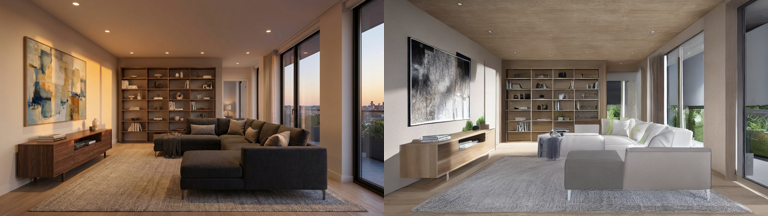

room1__img2img_0.5: auto flags = ['invented_or_removed'] | invented: armchair


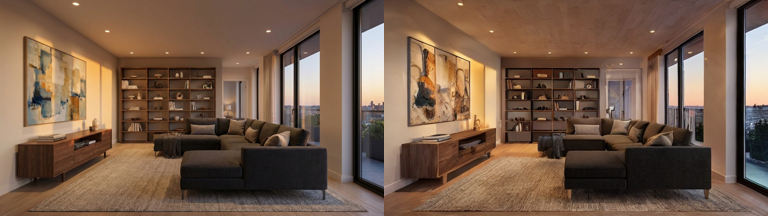

room1__img2img_0.7: auto flags = ['invented_or_removed'] | invented: armchair | removed: door


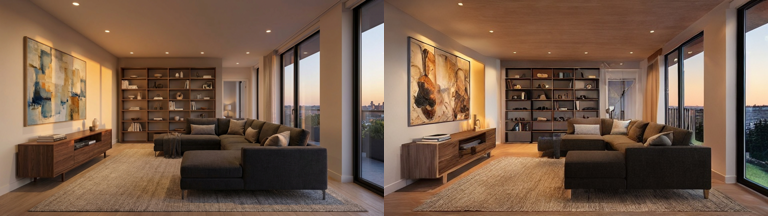

room1__img2img_0.9: auto flags = ['color_shift', 'invented_or_removed'] | removed: door, ottoman


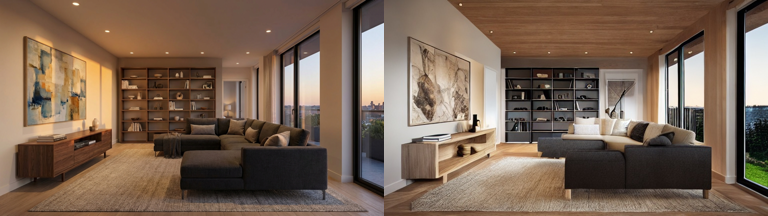

room1__inpaint_floor: auto flags = ['invented_or_removed'] | invented: armchair


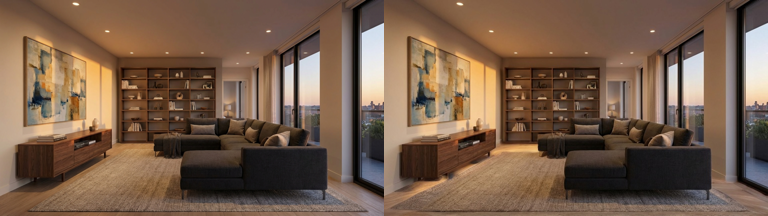

room2__canny_only: auto flags = ['color_shift']


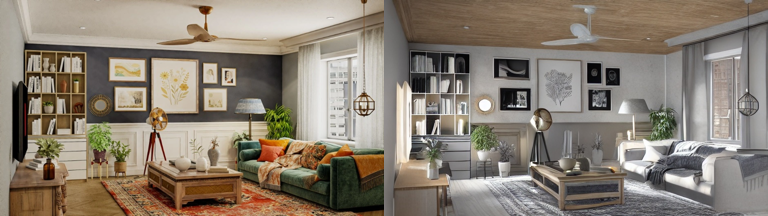

room2__img2img_0.5: auto flags = none


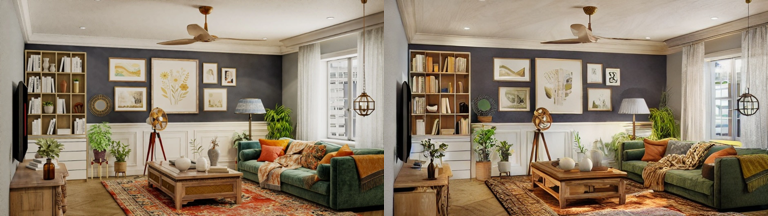

room2__img2img_0.7: auto flags = ['color_shift']


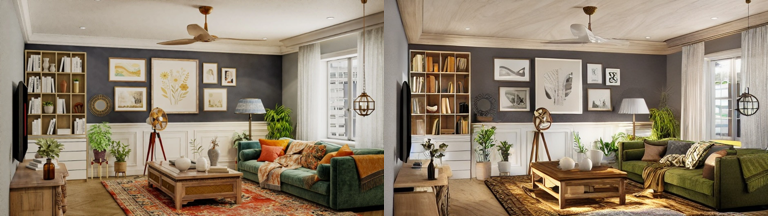

room2__img2img_0.9: auto flags = ['color_shift', 'invented_or_removed'] | removed: bookcase


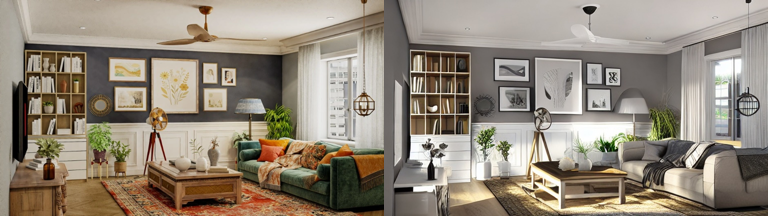

room2__inpaint_floor: auto flags = none


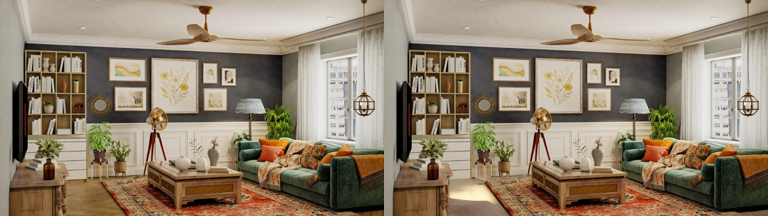

room3__canny_only: auto flags = ['color_shift', 'artwork_changed', 'invented_or_removed', 'layout_changed'] | invented: painting, screen | removed: rug


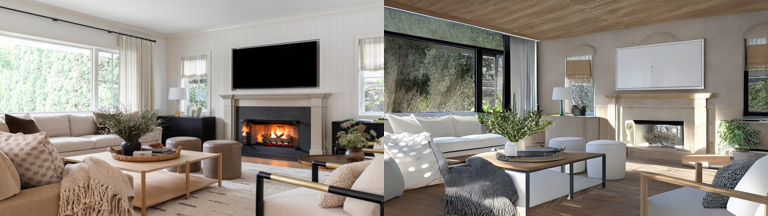

room3__img2img_0.5: auto flags = ['invented_or_removed'] | invented: cabinet


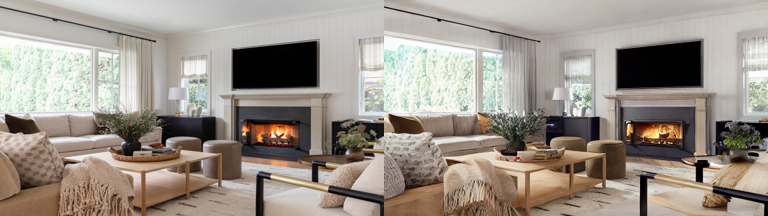

room3__img2img_0.7: auto flags = ['color_shift', 'artwork_changed', 'invented_or_removed'] | invented: cabinet, painting | removed: chair


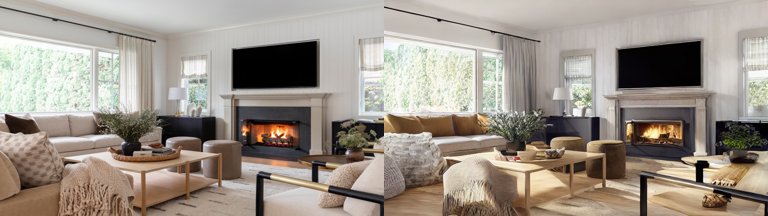

room3__img2img_0.9: auto flags = ['color_shift', 'invented_or_removed'] | invented: cabinet


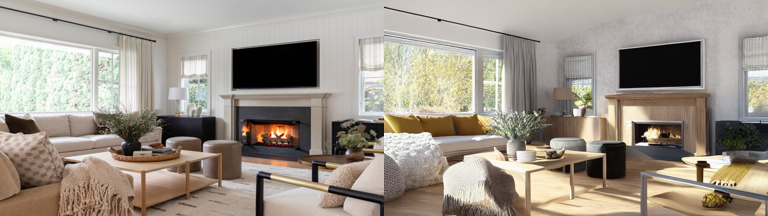

room3__inpaint_floor: auto flags = none


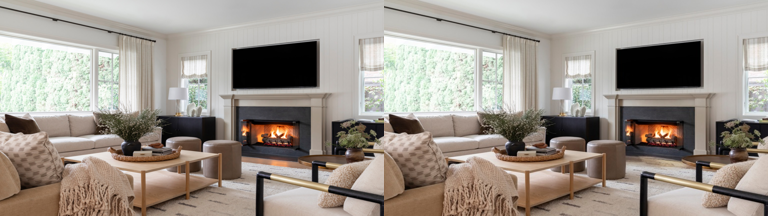

room4__canny_only: auto flags = ['color_shift', 'lost_structure', 'bent_lines', 'invented_or_removed'] | removed: fireplace


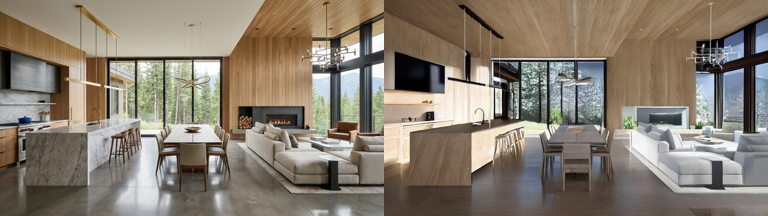

room4__img2img_0.5: auto flags = ['bent_lines', 'invented_or_removed'] | removed: kitchen island


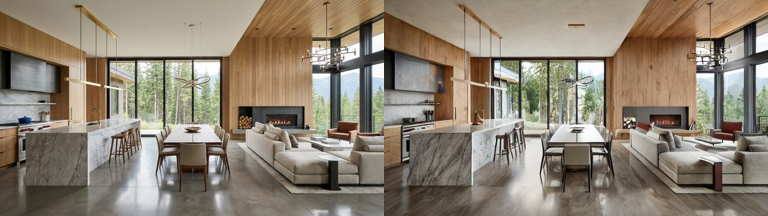

room4__img2img_0.7: auto flags = ['color_shift', 'invented_or_removed'] | removed: kitchen island


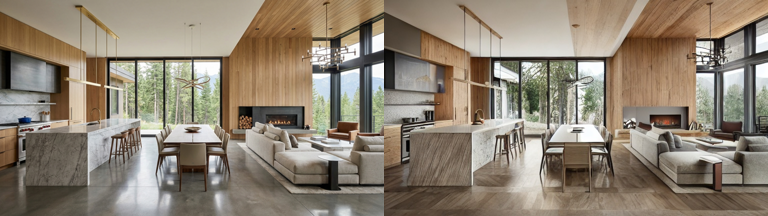

room4__img2img_0.9: auto flags = ['color_shift', 'bent_lines', 'invented_or_removed'] | removed: kitchen island


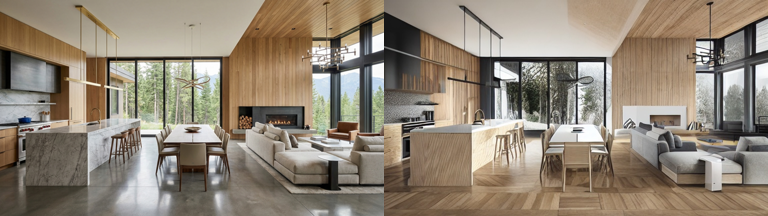

room4__inpaint_floor: auto flags = none


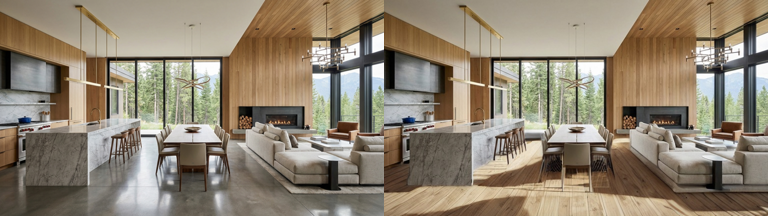

room5__canny_only: auto flags = ['color_shift', 'invented_or_removed'] | removed: door


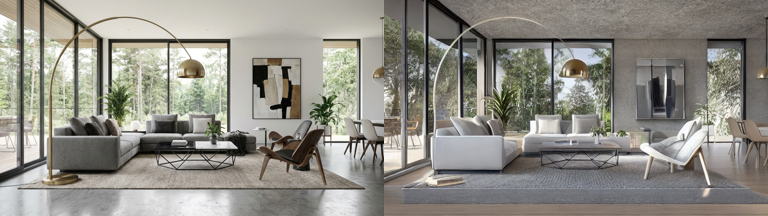

room5__img2img_0.5: auto flags = ['artwork_changed', 'invented_or_removed'] | invented: painting | removed: mirror


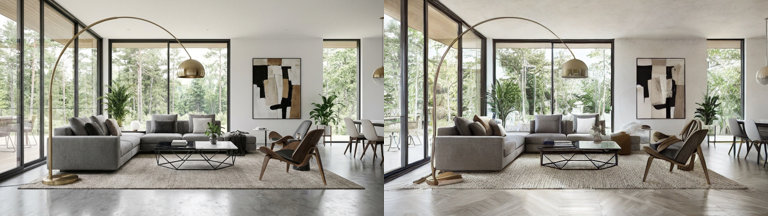

room5__img2img_0.7: auto flags = ['color_shift', 'artwork_changed', 'invented_or_removed'] | invented: painting | removed: mirror


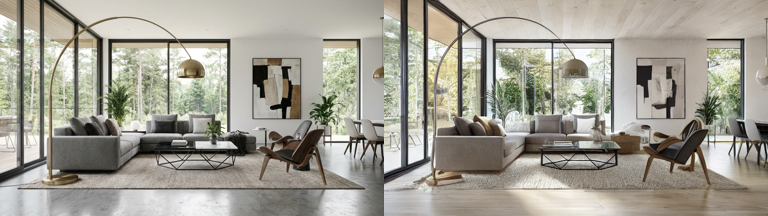

room5__img2img_0.9: auto flags = ['color_shift', 'artwork_changed', 'invented_or_removed'] | invented: painting | removed: mirror


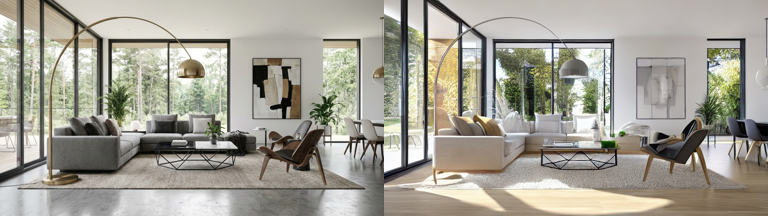

room5__inpaint_floor: auto flags = none


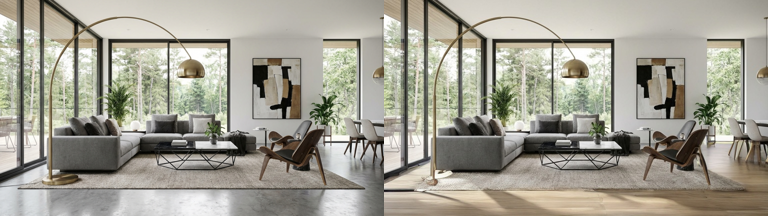

In [6]:
def pair(room, setting, scale=0.5):
    w, h = int(W * scale), int(H * scale)
    row = Image.new("RGB", (w * 2, h), "white")
    row.paste(originals[room].resize((w, h)), (0, 0)); row.paste(load(f"set/{room}__{setting}.jpg").resize((w, h)), (w, 0))
    return row

for _, r in auto.iterrows():
    flags = [f for f in FAILURES if r[f]]
    extra = (f" | invented: {r['invented']}" if r["invented"] else "") + (f" | removed: {r['removed']}" if r["removed"] else "")
    print(f"{r['render']}: auto flags = {flags or 'none'}{extra}")
    display(pair(r["room"], r["setting"]))

In [12]:
import io
from IPython.display import Image as IPImage

room1 → üst satır: original | canny_only | img2img_0.5  ·  alt satır: img2img_0.7 | img2img_0.9 | inpaint_floor


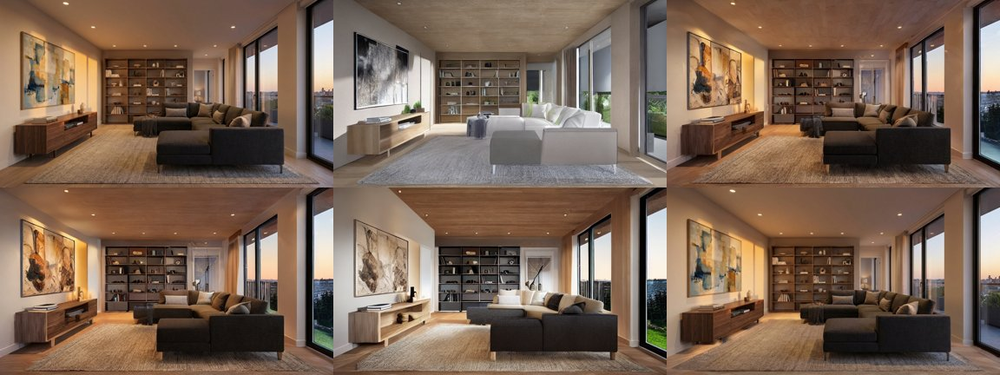

room2 → üst satır: original | canny_only | img2img_0.5  ·  alt satır: img2img_0.7 | img2img_0.9 | inpaint_floor


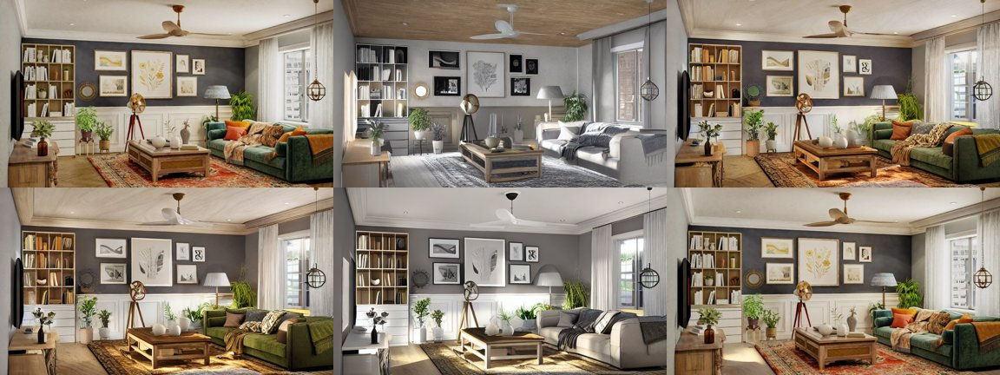

room3 → üst satır: original | canny_only | img2img_0.5  ·  alt satır: img2img_0.7 | img2img_0.9 | inpaint_floor


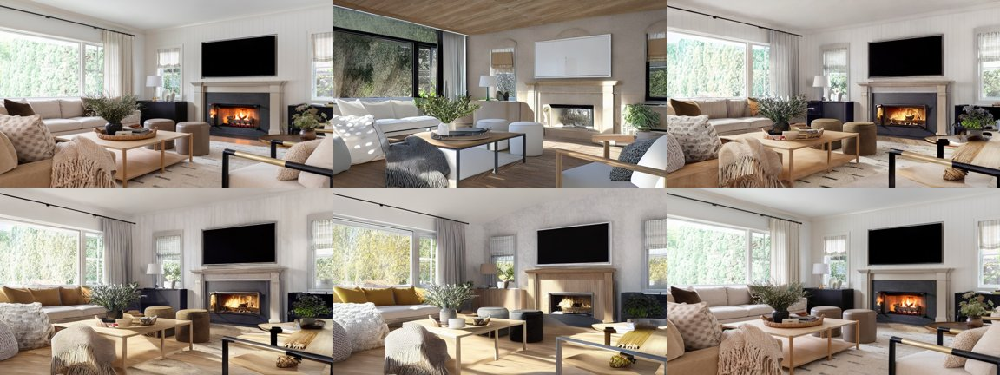

room4 → üst satır: original | canny_only | img2img_0.5  ·  alt satır: img2img_0.7 | img2img_0.9 | inpaint_floor


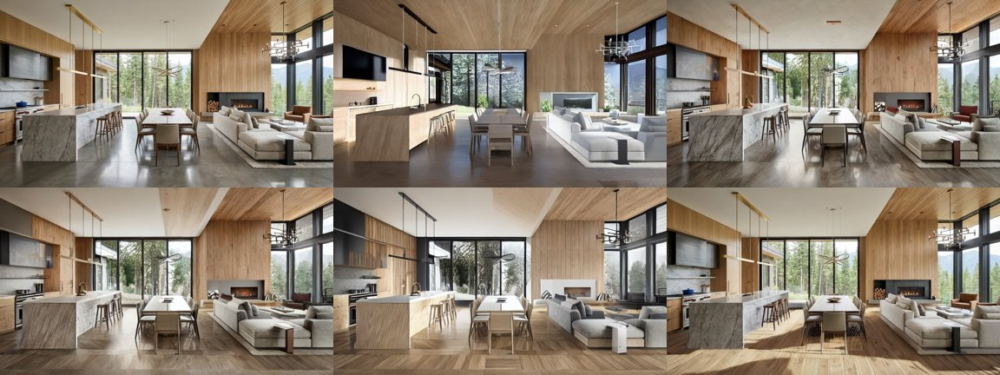

room5 → üst satır: original | canny_only | img2img_0.5  ·  alt satır: img2img_0.7 | img2img_0.9 | inpaint_floor


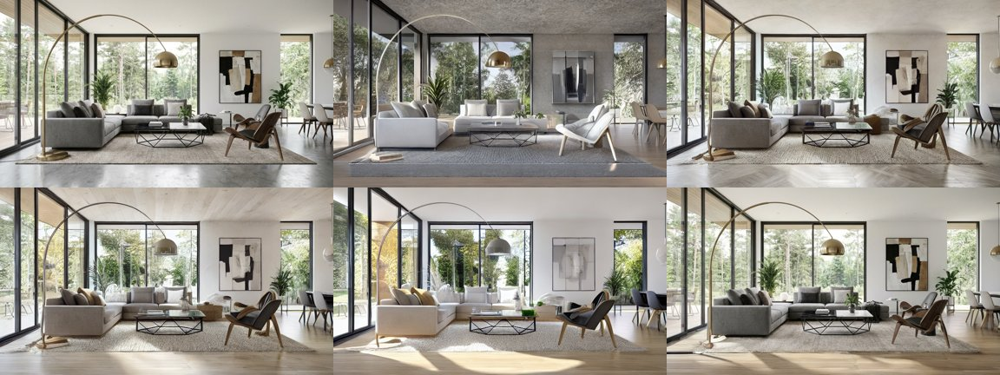

In [13]:
# Her oda için: original | canny_only | img2img_0.5 | img2img_0.7 | img2img_0.9 | inpaint_floor
SETTINGS_ORDER = ["canny_only", "img2img_0.5", "img2img_0.7", "img2img_0.9", "inpaint_floor"]
for room in originals:
    imgs = [originals[room]] + [load(f"set/{room}__{s}.jpg") for s in SETTINGS_ORDER]
    w, h = W // 2, H // 2
    grid = Image.new("RGB", (w * 3, h * 2), "white")
    for i, im in enumerate(imgs):
        grid.paste(im.resize((w, h)), ((i % 3) * w, (i // 3) * h))
    grid.save(f"{room}_grid.jpg", quality=90)
    print(room, "→ üst satır: original | canny_only | img2img_0.5  ·  alt satır: img2img_0.7 | img2img_0.9 | inpaint_floor")
    buf = io.BytesIO(); grid.save(buf, format="JPEG", quality=85); display(IPImage(data=buf.getvalue()))

In [7]:
# Write the failures YOU see for each render (use the names from FAILURES). Leave [] if it looks fine.
# FAILURES = color_shift, lost_structure, bent_lines, window_changed, artwork_changed, invented_or_removed, layout_changed
human = {render: [] for render in auto["render"]}

human["room1__canny_only"]    = ["color_shift", "artwork_changed"]
human["room1__img2img_0.5"]   = ["artwork_changed"]
human["room1__img2img_0.7"]   = ["color_shift", "artwork_changed"]
human["room1__img2img_0.9"]   = ["color_shift", "artwork_changed", "invented_or_removed"]
human["room1__inpaint_floor"] = []

human["room2__canny_only"]    = ["color_shift", "artwork_changed"]
human["room2__img2img_0.5"]   = ["artwork_changed"]
human["room2__img2img_0.7"]   = ["color_shift", "artwork_changed"]
human["room2__img2img_0.9"]   = ["color_shift", "artwork_changed"]
human["room2__inpaint_floor"] = []

human["room3__canny_only"]    = ["color_shift", "window_changed", "artwork_changed", "invented_or_removed"]
human["room3__img2img_0.5"]   = []
human["room3__img2img_0.7"]   = ["color_shift", "invented_or_removed"]
human["room3__img2img_0.9"]   = ["color_shift", "invented_or_removed"]
human["room3__inpaint_floor"] = []

human["room4__canny_only"]    = ["color_shift", "lost_structure", "invented_or_removed"]
human["room4__img2img_0.5"]   = []
human["room4__img2img_0.7"]   = ["color_shift", "invented_or_removed"]
human["room4__img2img_0.9"]   = ["color_shift", "invented_or_removed"]
human["room4__inpaint_floor"] = []

human["room5__canny_only"]    = ["color_shift", "artwork_changed", "invented_or_removed"]
human["room5__img2img_0.5"]   = []
human["room5__img2img_0.7"]   = ["color_shift", "artwork_changed"]
human["room5__img2img_0.9"]   = ["color_shift", "artwork_changed"]
human["room5__inpaint_floor"] = []

print("Renders:")
for k in human: print(" ", k)

Renders:
  room1__canny_only
  room1__img2img_0.5
  room1__img2img_0.7
  room1__img2img_0.9
  room1__inpaint_floor
  room2__canny_only
  room2__img2img_0.5
  room2__img2img_0.7
  room2__img2img_0.9
  room2__inpaint_floor
  room3__canny_only
  room3__img2img_0.5
  room3__img2img_0.7
  room3__img2img_0.9
  room3__inpaint_floor
  room4__canny_only
  room4__img2img_0.5
  room4__img2img_0.7
  room4__img2img_0.9
  room4__inpaint_floor
  room5__canny_only
  room5__img2img_0.5
  room5__img2img_0.7
  room5__img2img_0.9
  room5__inpaint_floor


## Part D: How good are the detectors?
For each failure type: **precision** (when the detector flags, was I seeing it too?) and **recall** (of the failures I saw, how many did it catch?). Low precision = false alarms, low recall = missed failures.

In [8]:
check = []
for f in FAILURES:
    pred = auto[f].values
    true = np.array([f in human.get(r, []) for r in auto["render"]])
    tp, fp, fn = int((pred & true).sum()), int((pred & ~true).sum()), int((~pred & true).sum())
    check.append({"failure": f, "seen by me": int(true.sum()), "flagged": int(pred.sum()), "both": tp,
                  "precision": tp / (tp + fp) if tp + fp else np.nan,
                  "recall": tp / (tp + fn) if tp + fn else np.nan})
check = pd.DataFrame(check).set_index("failure")
display(check.round(2))
print("Agreement on every (render, failure) pair:",
      f"{np.mean([[auto.loc[i, f] == (f in human.get(auto.loc[i, 'render'], [])) for f in FAILURES] for i in auto.index]):.0%}")

,seen by me,flagged,both,precision,recall
failure,,,,,
color_shift,15,14,14,1.00,0.93
lost_structure,1,1,1,1.00,1.00
bent_lines,0,3,0,0.00,NaN
window_changed,1,0,0,NaN,0.00
artwork_changed,12,5,3,0.60,0.25
invented_or_removed,8,18,8,0.44,1.00
layout_changed,0,1,0,0.00,NaN


Agreement on every (render, failure) pair: 85%


If a detector has many false alarms, raise or lower its threshold in `THRESH`, run Part B again and check again. Write down which thresholds you changed and why: this is the calibration step of an evaluation set.

## Part E: Triage report

,color_shift,lost_structure,bent_lines,window_changed,artwork_changed,invented_or_removed,layout_changed
setting,,,,,,,
inpaint_floor,0%,0%,0%,0%,0%,20%,0%
img2img_0.5,0%,0%,20%,0%,20%,80%,0%
img2img_0.7,80%,0%,0%,0%,40%,80%,0%
img2img_0.9,100%,0%,20%,0%,20%,100%,0%
canny_only,100%,20%,20%,0%,20%,80%,20%


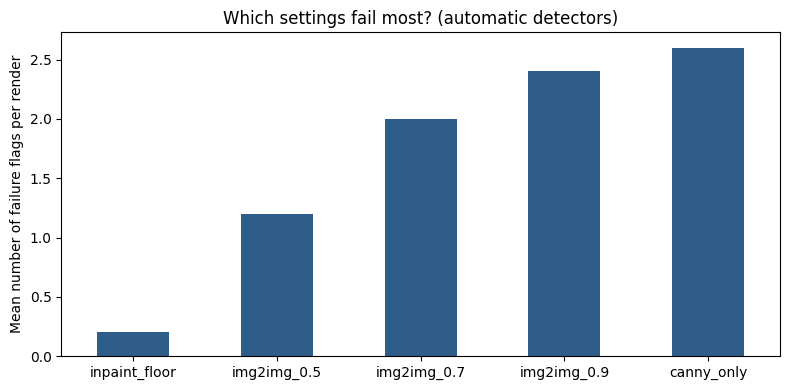

Worst renders:
  room3__canny_only: ['color_shift', 'artwork_changed', 'invented_or_removed', 'layout_changed']


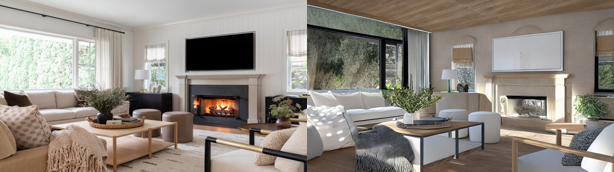

  room4__canny_only: ['color_shift', 'lost_structure', 'bent_lines', 'invented_or_removed']


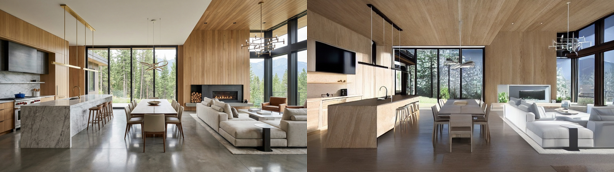

  room4__img2img_0.9: ['color_shift', 'bent_lines', 'invented_or_removed']


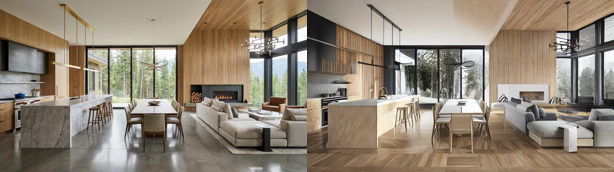

  room5__img2img_0.9: ['color_shift', 'artwork_changed', 'invented_or_removed']


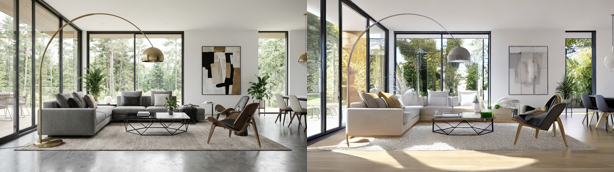

In [9]:
import matplotlib.pyplot as plt
order = ["inpaint_floor", "img2img_0.5", "img2img_0.7", "img2img_0.9", "canny_only"]
order = [s for s in order if s in set(auto["setting"])] + sorted(set(auto["setting"]) - set(order))
rate = auto.groupby("setting")[FAILURES].mean().reindex(order)
display((rate * 100).round(0).astype(int).astype(str) + "%")

fig, ax = plt.subplots(figsize=(8, 4))
rate.sum(1).plot.bar(ax=ax, color="#2f5d8a")
ax.set_ylabel("Mean number of failure flags per render"); ax.set_xlabel("")
ax.set_title("Which settings fail most? (automatic detectors)")
plt.xticks(rotation=0); plt.tight_layout(); plt.savefig("exp6_failures_by_setting.png", dpi=150); plt.show()

worst = auto.sort_values(["n_failures", "ΔE"], ascending=False).head(4)
print("Worst renders:")
for _, r in worst.iterrows():
    print(f"  {r['render']}: {[f for f in FAILURES if r[f]]}")
    pair(r["room"], r["setting"]).save(f"exp6_worst_{r['render']}.jpg", quality=90)
    display(pair(r["room"], r["setting"], scale=0.4))

**What I saw.**

* **Settings:** the automatic flags rank the settings in the same order as my earlier experiments: `inpaint_floor` is the safest (0.2 flags per render), then `img2img_0.5` (1.2), `img2img_0.7` (2.0), `img2img_0.9` (2.4) and `canny_only` (2.6). The worst renders were `canny_only` in the fireplace room (the TV became a white panel, a new window appeared, the rug disappeared) and `canny_only` / `img2img_0.9` in the open-plan room (the marble island turned into wood, the range hood became a TV, the fireplace became a white box).
* **Detectors that worked well:** **color shift** caught 14 of the 15 color failures I saw with no false alarms (precision 1.00, recall 0.93); its one miss was a ceiling that turned into wood while the whole-image ΔE (8.9) stayed under the threshold of 10. **Lost structure** flagged the one render where kitchen details disappeared, and nothing else.
* **Detectors with false alarms or misses, and why:**
  * **Invented or removed objects** caught all 8 real cases (recall 1.00) but raised 18 alarms (precision 0.44). The segmentation model gives the same object different names in the two images (a painting called "mirror" in the original and "painting" in the render, part of a sofa called "armchair"). In 4 of its 8 correct alarms it also named the wrong object, for example "kitchen island removed" when the island only changed material and a firewood stack disappeared.
  * **Artwork changed** caught only 3 of the 12 changed paintings (recall 0.25). It checks *where* a painting is (IoU of the painting mask), not *what* is in it, so a painting that stays in place but changes its content or colors is missed.
  * **Window changed** missed the only real case: a new window overlapped the old one enough to pass the IoU check.
  * **Bent lines** (3 alarms) and **layout changed** (1 alarm) found nothing I could see.

**Result.** The detectors are useful for ranking settings, and color shift and lost structure can be trusted on their own. The object detector never missed a real case, but more than half of its alarms were false, so every alarm needs a human look. The artwork and window detectors give false confidence: they missed most real changes. The overall agreement (85%) hides this, because most render × failure pairs are "no failure" for both me and the detectors. An automatic evaluation set needs human labels to calibrate it before its numbers can be trusted. Labeling also needs care: checking every render at full size instead of small grids changed the labels of 9 of the 25 renders.

**Limits.** Few rooms and one seed. Segmentation can be wrong on unusual renders, which affects the window, artwork, object and layout checks. ΔE on the whole image also counts the floor, which was changed on purpose; the thresholds should be set per task. Human labels are from one person (me).

## Download

In [14]:
auto.to_csv("exp6_auto_flags.csv", index=False)
check.to_csv("exp6_detector_check.csv")
pd.Series({k: ", ".join(v) for k, v in human.items()}).to_csv("exp6_human_labels.csv")
!zip -q -r exp6_results.zip set exp6_*.jpg exp6_*.png exp6_*.csv
files.download("exp6_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>